# Đáp án mã · Bài 0 — Khởi động và dữ liệu

Notebook này giải **các bài tập của Bài 0** bằng mã chạy được. Hãy tự làm trước, rồi đối chiếu. Mã dùng lại tiện ích `nlpvi` và dữ liệu `data/reviews_vi.csv`.

> Đáp án không phải là duy nhất. Nếu cách làm của bạn khác nhưng cho cùng kết luận và bạn giải thích được vì sao, đó cũng là đáp án đúng.

In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")

ROOT = pathlib.Path.cwd()
while not (ROOT / "nlpvi").exists():          # tìm thư mục gốc dự án, dù notebook nằm ở đâu
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from nlpvi import LABELS, load_reviews, normalize, strip_accents, set_seed

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
set_seed(42)
df = load_reviews()
df["so_am_tiet"] = df["text"].str.split().str.len()
print(df.shape)

(1800, 6)


## Bài tập 1 — Độ dài trung bình theo nhãn

*Tính độ dài trung bình (số âm tiết) theo từng nhãn. Nhãn nào dài nhất? Giả thuyết vì sao?*

In [2]:
tbl = df.groupby("label")["so_am_tiet"].agg(["mean", "median", "std", "count"]).round(2)
tbl.loc[LABELS]

,mean,median,std,count
label,,,,
tích cực,11.27,11.0,4.83,824
tiêu cực,11.10,11.0,4.94,645
trung tính,12.51,12.0,5.37,331


**Đọc kết quả.** Nhãn *trung tính* dài nhất (≈12,5 âm tiết so với ≈11,1–11,3 của hai nhãn còn lại); *tích cực* và *tiêu cực* gần như bằng nhau. Giả thuyết hợp lý cho dữ liệu này: câu trung tính gồm các khuôn dài ("Ưu điểm: … Nhược điểm: …" và câu mô tả bối cảnh), còn câu tích cực/tiêu cực hay chỉ một mệnh đề. Với dữ liệu thật, người ta hay giả thuyết rằng phản hồi *tiêu cực* dài hơn vì người viết nêu lý do — nhưng ở đây điều đó **không** xảy ra. Đừng suy từ trực giác; hãy kiểm chứng. Ô dưới dùng bootstrap: chênh lệch trung tính − tích cực ≈ +1,2 âm tiết, khoảng 95% [+0,55; +1,96] không chứa 0 nên chênh lệch này có thật (dù nhỏ).

In [3]:
rng = np.random.default_rng(0)
a = df.loc[df["label"] == "trung tính", "so_am_tiet"].values
b = df.loc[df["label"] == "tích cực", "so_am_tiet"].values
hieu = [rng.choice(a, len(a)).mean() - rng.choice(b, len(b)).mean() for _ in range(2000)]
print(f"trung tính − tích cực: {a.mean() - b.mean():+.2f} âm tiết; bootstrap 95% = [{np.percentile(hieu, 2.5):+.2f}, {np.percentile(hieu, 97.5):+.2f}]")

trung tính − tích cực: +1.24 âm tiết; bootstrap 95% = [+0.55, +1.96]


## Bài tập 2 — Tỉ lệ nhãn theo miền (cột chồng)

*Vẽ biểu đồ cột chồng thể hiện tỉ lệ ba nhãn trong từng miền. Miền nào lệch nhãn nhiều nhất?*

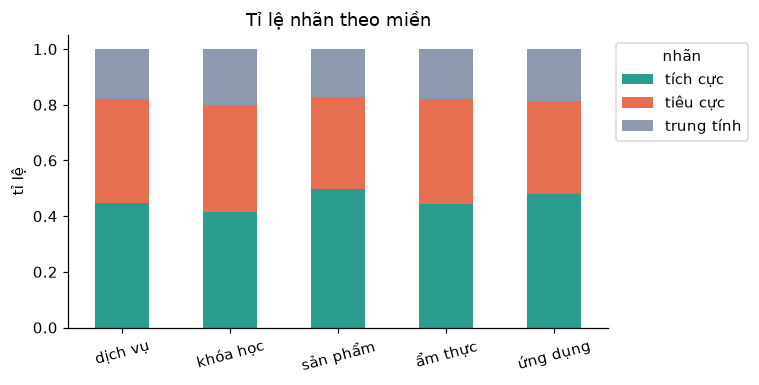

Độ lệch so với phân phối chung (0 = giống hệt):
domain
khóa học    0.043
sản phẩm    0.041
ứng dụng    0.025
ẩm thực     0.018
dịch vụ     0.016


In [4]:
ti_le = pd.crosstab(df["domain"], df["label"], normalize="index")[LABELS]
ax = ti_le.plot.bar(stacked=True, color=["#2a9d8f", "#e76f51", "#8d99ae"], figsize=(7, 3.6), rot=15)
ax.set_ylabel("tỉ lệ"); ax.set_xlabel(""); ax.set_title("Tỉ lệ nhãn theo miền"); ax.legend(title="nhãn", bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

# "lệch" = khoảng cách tới phân phối chung (tổng biến thiên)
chung = df["label"].value_counts(normalize=True).reindex(LABELS)
lech = (ti_le - chung).abs().sum(axis=1) / 2
print("Độ lệch so với phân phối chung (0 = giống hệt):")
print(lech.sort_values(ascending=False).round(3).to_string())

**Đọc kết quả.** Độ lệch nhỏ (cao nhất ≈4% ở *khóa học* và *sản phẩm*) ở mọi miền, vì bộ dữ liệu tổng hợp được sinh với *cùng* tỉ lệ nhãn cho mọi miền. Với dữ liệu thật, bạn thường thấy lệch mạnh hơn (ví dụ miền "dịch vụ công" nhiều tiêu cực) và đó là một **đặc trưng cần lưu ý khi chia tập và khi mô hình bị hỏi ngoài miền**. Cũng nhớ: mẫu mỗi miền chỉ vài trăm nên một chênh lệch vài phần trăm có thể chỉ là nhiễu lấy mẫu.

## Bài tập 3 — Mở rộng `khoa_trung` để gộp teencode

*Tỉ lệ trùng ẩn tăng bao nhiêu khi gộp cả teencode (`ko`→`không`, `dc`→`được`)?*

In [5]:
def khoa(text, teencode):
    t = strip_accents(normalize(text, expand_teencode=teencode, emoji="drop"))
    return re.sub(r"[^a-z0-9 ]", "", t.lower()).strip()

def ti_le_trung(teencode):
    k = df["text"].map(lambda x: khoa(x, teencode))
    tap = {s: set(k[df["split"] == s]) for s in ["train", "valid", "test"]}
    return {s: round(k[df["split"] == s].isin(tap["train"]).mean(), 4) for s in ["valid", "test"]}, k.nunique()

(tl0, n0), (tl1, n1) = ti_le_trung(False), ti_le_trung(True)
pd.DataFrame({"không gộp teencode": {**{f"trùng ẩn {k}": v for k, v in tl0.items()}, "số khóa duy nhất": n0},
              "gộp teencode": {**{f"trùng ẩn {k}": v for k, v in tl1.items()}, "số khóa duy nhất": n1}})

,không gộp teencode,gộp teencode
trùng ẩn valid,0.0483,0.0483
trùng ẩn test,0.0520,0.0520
số khóa duy nhất,1742.0000,1741.0000


**Đọc kết quả.** Kết quả **gần như không đổi**: tỉ lệ trùng ẩn vẫn ≈4,8% (valid) và ≈5,2% (test); số khóa duy nhất chỉ giảm đúng 1 (1742 → 1741). Lý do: chỉ ~12% mẫu có teencode và các biến thể teencode hầu như không rơi vào cặp câu trùng. Đây là một kết quả âm tính hữu ích: **một phép chuẩn hóa chỉ đáng thêm vào nếu bạn đo được nó tìm ra thêm bản sao** — đừng giả định. (Trên bình luận thật, nơi teencode phổ biến hơn nhiều, kết quả có thể khác.)

## Bài tập 4 — Chia lại ngẫu nhiên và `stratify`

*Chia ngẫu nhiên bằng `train_test_split(..., random_state=0)` rồi so tỉ lệ nhãn với cột `split`. Vì sao nên dùng `stratify=`?*

In [6]:
from sklearn.model_selection import train_test_split

def phan_phoi(y):
    return y.value_counts(normalize=True).reindex(LABELS).round(3)

tr0, te0 = train_test_split(df, test_size=0.15, random_state=0)                              # không stratify
tr1, te1 = train_test_split(df, test_size=0.15, random_state=0, stratify=df["label"])        # có stratify
cot = df[df["split"] == "test"]["label"]
pd.DataFrame({"toàn bộ": phan_phoi(df["label"]), "cột split=test": phan_phoi(cot),
              "ngẫu nhiên (không stratify)": phan_phoi(te0["label"]), "ngẫu nhiên + stratify": phan_phoi(te1["label"])})

,toàn bộ,cột split=test,ngẫu nhiên (không stratify),ngẫu nhiên + stratify
label,,,,
tích cực,0.458,0.509,0.437,0.456
tiêu cực,0.358,0.342,0.400,0.359
trung tính,0.184,0.149,0.163,0.185


In [7]:
# Độ biến thiên của tỉ lệ 'trung tính' trong tập test khi đổi seed: stratify làm nó gần như cố định
tl = lambda seed, strat: train_test_split(df, test_size=0.15, random_state=seed, stratify=df["label"] if strat else None)[1]["label"].eq("trung tính").mean()
print("tỉ lệ 'trung tính' trong test qua 10 seed:")
print("  không stratify:", np.round([tl(s, False) for s in range(10)], 3), "| độ lệch chuẩn", round(np.std([tl(s, False) for s in range(10)]), 4))
print("  có stratify   :", np.round([tl(s, True) for s in range(10)], 3), "| độ lệch chuẩn", round(np.std([tl(s, True) for s in range(10)]), 4))

tỉ lệ 'trung tính' trong test qua 10 seed:
  không stratify: [0.163 0.23  0.181 0.17  0.17  0.159 0.17  0.181 0.181 0.159] | độ lệch chuẩn 0.0195
  có stratify   : [0.185 0.185 0.185 0.185 0.185 0.185 0.185 0.185 0.185 0.185] | độ lệch chuẩn 0.0


**Đọc kết quả.** Không stratify, tỉ lệ nhãn hiếm (*trung tính* ≈ 18%) trong tập test **dao động** theo seed; có stratify, nó gần như đứng yên. Với lớp rất hiếm (vài %), chia không stratify có thể khiến tập test gần như thiếu hẳn lớp đó. Lưu ý thêm: cột `split` của khóa học chia bằng *băm `id`* (tất định, ổn định khi thêm dữ liệu) — tỉ lệ nhãn xấp xỉ nhưng không *chính xác* như stratify, nên đủ tốt cho kho đủ lớn.

## Bài tập 5 (khó) — Rò rỉ theo nhóm và `GroupShuffleSplit`

*Giả sử mỗi `id` thuộc một "người dùng" `int(id[1:]) % 200`. Có người dùng nào xuất hiện ở cả train và test không? Đề xuất chia theo nhóm.*

In [8]:
from sklearn.model_selection import GroupShuffleSplit

df["nguoi_dung"] = df["id"].str[1:].astype(int) % 200
nd = {s: set(df.loc[df["split"] == s, "nguoi_dung"]) for s in ["train", "valid", "test"]}
print(f"người dùng ở cả train và test (chia theo cột split): {len(nd['train'] & nd['test'])}/200")

gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=0)
i_tr, i_te = next(gss.split(df, groups=df["nguoi_dung"]))
g_tr, g_te = set(df.iloc[i_tr]["nguoi_dung"]), set(df.iloc[i_te]["nguoi_dung"])
print(f"chia theo nhóm: người dùng ở cả hai tập = {len(g_tr & g_te)} | số mẫu train/test = {len(i_tr)}/{len(i_te)}")
print("tỉ lệ nhãn test (nhóm):", phan_phoi(df.iloc[i_te]["label"]).to_dict())

người dùng ở cả train và test (chia theo cột split): 164/200
chia theo nhóm: người dùng ở cả hai tập = 0 | số mẫu train/test = 1530/270
tỉ lệ nhãn test (nhóm): {'tích cực': 0.481, 'tiêu cực': 0.359, 'trung tính': 0.159}


**Đọc kết quả.** Chia theo cột `split` (băm theo *mẫu*) khiến hầu hết người dùng xuất hiện ở cả train và test — nếu bình luận của cùng một người có phong cách giống nhau, mô hình sẽ "nhận ra người viết" thay vì học cảm xúc: **rò rỉ theo nhóm**. `GroupShuffleSplit` đảm bảo mỗi người chỉ ở một tập. Cái giá: tỉ lệ nhãn của tập test có thể lệch hơn (vì chia theo nhóm, không theo mẫu), nên nên kết hợp với kiểm tra phân phối nhãn, hoặc dùng `StratifiedGroupKFold` khi cần cả hai.

(Ở bộ dữ liệu tổng hợp này, "người dùng" là một khái niệm giả định để thực hành kỹ thuật.)